Logistic Regression  average predicted risk: 0.2212   (real rate: 0.2212)
Decision Tree        average predicted risk: 0.2206   (real rate: 0.2212)
Random Forest        average predicted risk: 0.2214   (real rate: 0.2212)
XGBoost              average predicted risk: 0.2211   (real rate: 0.2212)


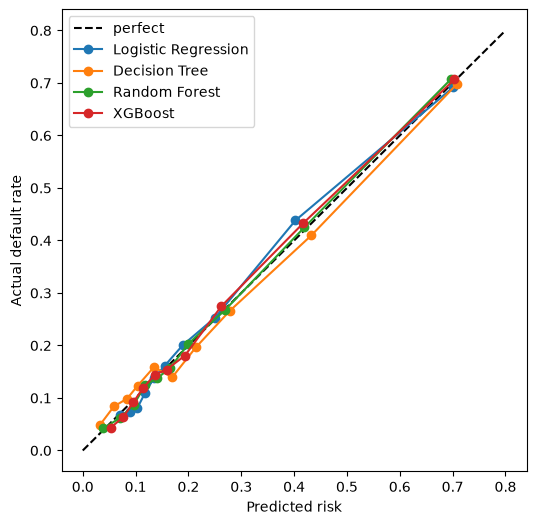

In [1]:
import sys
sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.calibration import calibration_curve
from src.features import split_xy
from src.tune import load_tuned_models

train = pd.read_csv("../data/processed/train.csv")
X, y = split_xy(train)
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

models = load_tuned_models()
oof = {}
for name, model in models.items():
    oof[name] = cross_val_predict(model, X, y, cv = cv, method = "predict_proba")[:, 1]
    print(f"{name:20s} average predicted risk: {oof[name].mean():.4f}   (real rate: {y.mean():.4f})")

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 0.8], [0, 0.8], "k--", label="perfect")
for name, p in oof.items():
    true_rate, pred_rate = calibration_curve(y, p, n_bins = 10, strategy = "quantile")
    ax.plot(pred_rate, true_rate, marker = "o", label = name)
ax.set_xlabel("Predicted risk")
ax.set_ylabel("Actual default rate")
ax.legend()
plt.show()

All four models are well calibrated. Average predicted risk matches the real default rate (0.221). Tree is slightly jumpier.